In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.cox import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

import jinja2

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../data/encoding/data_new.csv")

diagnosis_variables = []
with open("../data/encoding/diagnosis_new.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/encoding/treatment_new.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

'''surgery_variables = []
with open("../data/encoding/surgery_new.txt", "r") as file:
    for line in file:
        surgery_variables.append(line.strip())'''

''' cols_to_remove = ['Final pathology', 'Final recommendations to patient']

removed = []
for c in cols_to_remove:
    if c in diagnosis_variables:
        diagnosis_variables.remove(c)
        removed.append(c)

# Also drop these columns from the dataframe so they won't appear in survival_dataset
if removed:
    dataset = dataset.drop(columns=removed, errors='ignore')'''

feature_columns = treatment_variables + diagnosis_variables # + surgery_variables

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

In [3]:
binary_features = []
continuous_features = []

In [4]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [5]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']
event_indicator = survival_dataset['Regional LN recurrence']

In [6]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

In [7]:
for train_idx, val_idx in cv:
    print("Train events:", survival_dataset.iloc[train_idx]["Regional LN recurrence"].sum())
    print("Val events:", survival_dataset.iloc[val_idx]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0


In [8]:
print("Train events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Val events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0


In [9]:
x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]
sgkf_1 = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

In [10]:
# Scale features for FINAL MODEL training and test evaluation
# NOTE: This scaling is ONLY for final model training after CV hyperparameter selection
# During CV, scaling happens INSIDE each fold (see cox_cross_validation function)
# Without scaling, L1 penalty affects features with different ranges unequally

scaler = MinMaxScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# convert scaled arrays back to DataFrame (preserve original columns and indices)
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns, index=x_test.index)

In [11]:
l1_ratio = 0.9
model = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio)
alphas = np.logspace(-3.7, -2, 10)
list_alphas = alphas.tolist()
alphas = pd.DataFrame(list_alphas, columns=['Alphas'])

In [12]:
from functions.cox import cox_grid_search, plot_cox_grid_search_results

# Define hyperparameter ranges
alpha_range = np.logspace(-3, -1, 10)
l1_ratio_range = [1.0, 0.8, 0.5, 0.1, 0.01, 0.001]

metrics = ['c-index', 'c-index-ipcw', 'int-brier-score']

# Run grid search
results, best_params, summary_df = cox_grid_search(
    X=x_train,  # Pass UNSCALED data
    y=y_train,
    cv_folds=sgkf_1,
    alpha_range=alpha_range,
    l1_ratio_range=l1_ratio_range,
    metrics=metrics,
    scaler_class='standard',  # or 'mixed' with binary/continuous features
    verbose=True
)


COX MODEL GRID SEARCH
L1 ratios: [1.0, 0.8, 0.5, 0.1, 0.01, 0.001]
Alphas: 10 values from 1.00e-03 to 1.00e-01
Total combinations: 60
Scaler: standard

[1/60] l1=1.000, alpha=1.00e-03 (elapsed: 0.0min, est. remaining: 0.0min)
[2/60] l1=1.000, alpha=1.67e-03 (elapsed: 0.0min, est. remaining: 0.4min)
[3/60] l1=1.000, alpha=2.78e-03 (elapsed: 0.0min, est. remaining: 0.4min)
[4/60] l1=1.000, alpha=4.64e-03 (elapsed: 0.0min, est. remaining: 0.5min)
[5/60] l1=1.000, alpha=7.74e-03 (elapsed: 0.0min, est. remaining: 0.5min)
[6/60] l1=1.000, alpha=1.29e-02 (elapsed: 0.1min, est. remaining: 0.5min)


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)


[7/60] l1=1.000, alpha=2.15e-02 (elapsed: 0.1min, est. remaining: 0.5min)


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)


[8/60] l1=1.000, alpha=3.59e-02 (elapsed: 0.1min, est. remaining: 0.5min)


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)


... (21 outputs left out)

c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)


[31/60] l1=0.100, alpha=1.00e-03 (elapsed: 0.4min, est. remaining: 0.4min)
[32/60] l1=0.100, alpha=1.67e-03 (elapsed: 0.4min, est. remaining: 0.4min)
[33/60] l1=0.100, alpha=2.78e-03 (elapsed: 0.4min, est. remaining: 0.3min)
[34/60] l1=0.100, alpha=4.64e-03 (elapsed: 0.4min, est. remaining: 0.3min)
[35/60] l1=0.100, alpha=7.74e-03 (elapsed: 0.4min, est. remaining: 0.3min)
[36/60] l1=0.100, alpha=1.29e-02 (elapsed: 0.5min, est. remaining: 0.3min)
[37/60] l1=0.100, alpha=2.15e-02 (elapsed: 0.5min, est. remaining: 0.3min)
[38/60] l1=0.100, alpha=3.59e-02 (elapsed: 0.5min, est. remaining: 0.3min)
[39/60] l1=0.100, alpha=5.99e-02 (elapsed: 0.5min, est. remaining: 0.3min)
[40/60] l1=0.100, alpha=1.00e-01 (elapsed: 0.5min, est. remaining: 0.3min)


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)


[41/60] l1=0.010, alpha=1.00e-03 (elapsed: 0.5min, est. remaining: 0.2min)
[42/60] l1=0.010, alpha=1.67e-03 (elapsed: 0.5min, est. remaining: 0.2min)
[43/60] l1=0.010, alpha=2.78e-03 (elapsed: 0.6min, est. remaining: 0.2min)
[44/60] l1=0.010, alpha=4.64e-03 (elapsed: 0.6min, est. remaining: 0.2min)
[45/60] l1=0.010, alpha=7.74e-03 (elapsed: 0.6min, est. remaining: 0.2min)
[46/60] l1=0.010, alpha=1.29e-02 (elapsed: 0.6min, est. remaining: 0.2min)
[47/60] l1=0.010, alpha=2.15e-02 (elapsed: 0.6min, est. remaining: 0.2min)
[48/60] l1=0.010, alpha=3.59e-02 (elapsed: 0.6min, est. remaining: 0.2min)
[49/60] l1=0.010, alpha=5.99e-02 (elapsed: 0.6min, est. remaining: 0.1min)
[50/60] l1=0.010, alpha=1.00e-01 (elapsed: 0.7min, est. remaining: 0.1min)
[51/60] l1=0.001, alpha=1.00e-03 (elapsed: 0.7min, est. remaining: 0.1min)
[52/60] l1=0.001, alpha=1.67e-03 (elapsed: 0.7min, est. remaining: 0.1min)
[53/60] l1=0.001, alpha=2.78e-03 (elapsed: 0.7min, est. remaining: 0.1min)
[54/60] l1=0.001, alpha=4

{'c-index': {'l1_ratio': np.float64(1.0), 'alpha': np.float64(0.0016681005372000592), 'mean': np.float64(0.8546370559647104), 'std': np.float64(0.10942930579575448)}, 'c-index-ipcw': {'l1_ratio': np.float64(1.0), 'alpha': np.float64(0.0016681005372000592), 'mean': np.float64(0.7235445767220843), 'std': np.float64(0.1580482799867941)}, 'int-brier-score': {'l1_ratio': np.float64(1.0), 'alpha': np.float64(0.0027825594022071257), 'mean': np.float64(0.018822876151380976), 'std': np.float64(0.0063648088552539185)}}


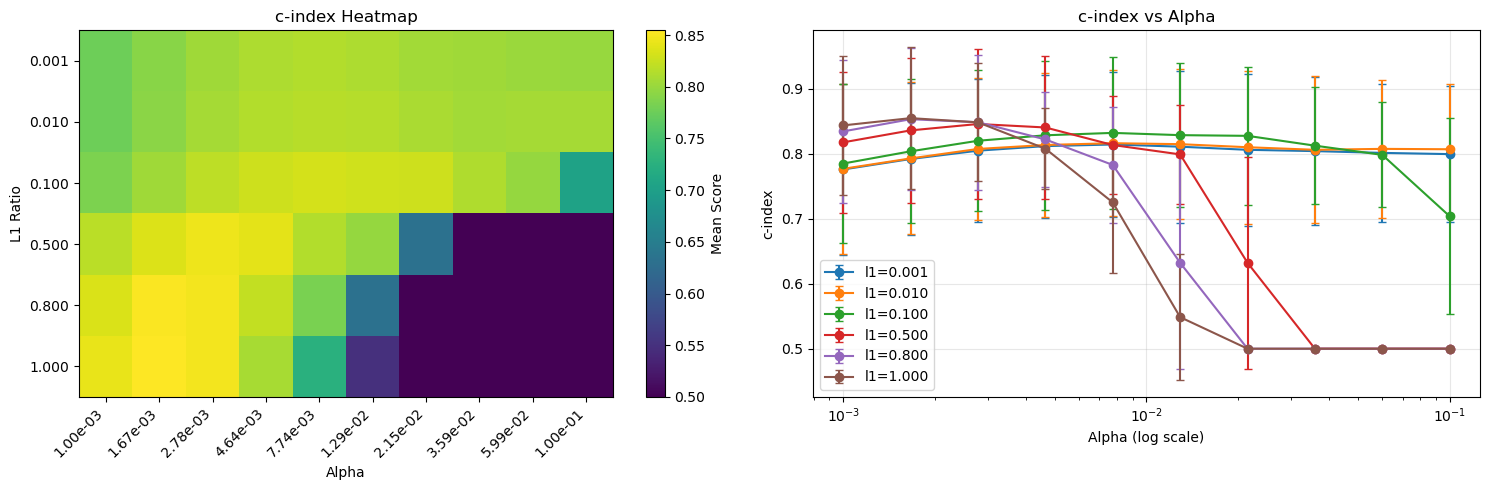

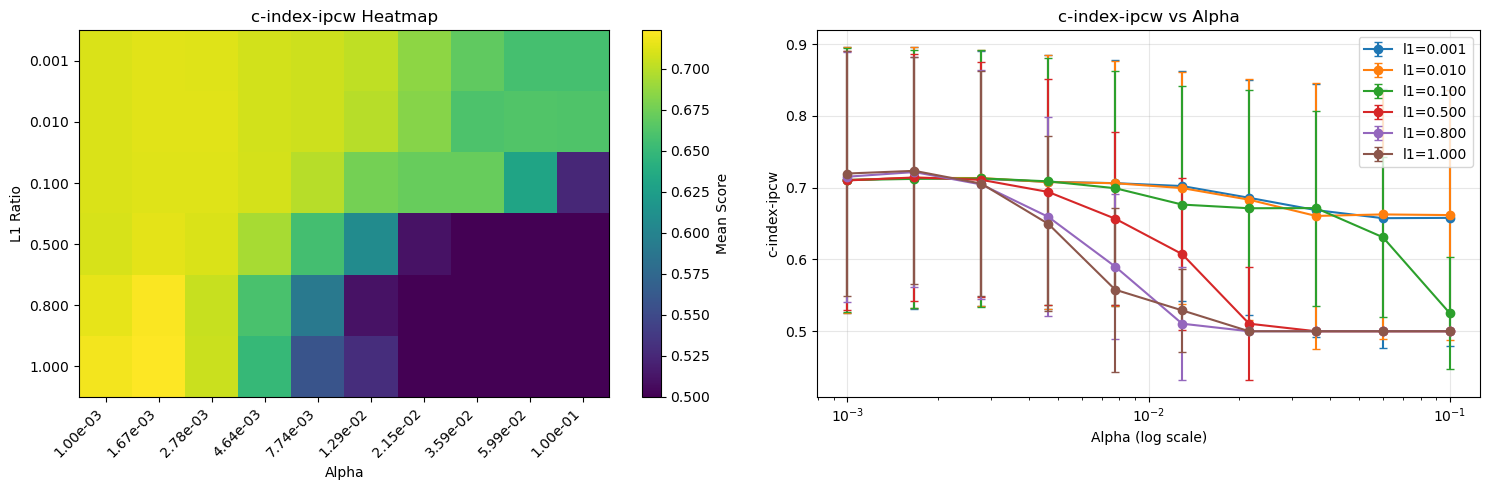

In [13]:
# Check best parameters
print(best_params)

# Visualize
plot_cox_grid_search_results(summary_df, metric='c-index')
plot_cox_grid_search_results(summary_df, metric='c-index-ipcw')

In [80]:
# Test multiple alpha values to find the best one
results_all_alphas = {}
metrics = ['c-index', 'c-index-ipcw', 'int-brier-score']

for alpha in list_alphas:
    print(f"Testing alpha: {alpha:.4f}")
    results_df = cox_cross_validation(x_train, y_train, sgkf_1, alpha=alpha, l1_ratio=l1_ratio, metrics=metrics, scaler_class='minmax', 
                                      binary_features=binary_features, continuous_features=continuous_features)
    results_all_alphas[alpha] = results_df

Testing alpha: 0.0002
Testing alpha: 0.0003
Testing alpha: 0.0005
Testing alpha: 0.0007
Testing alpha: 0.0011
Testing alpha: 0.0018
Testing alpha: 0.0027
Testing alpha: 0.0042


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)


Testing alpha: 0.0065


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)


Testing alpha: 0.0100


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)
c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\cox.py:46: UserWarning: all coefficients are zero, consider decreasing alpha.
  model.fit(X_train, y_train)


In [81]:
# Get summaries for each metric
cindex_summary = create_alpha_summary(results_all_alphas, 'c-index')
ipcw_summary = create_alpha_summary(results_all_alphas, 'c-index-ipcw')
brier_summary = create_alpha_summary(results_all_alphas, 'int-brier-score')

print("C-Index Results:")
print(cindex_summary.sort_values('Mean', ascending=False).head())
print("\nIPCW C-Index Results:")
print(ipcw_summary.sort_values('Mean', ascending=False).head())
print("\nBrier Score Results (lower is better):")
print(brier_summary.sort_values('Mean', ascending=True).head())

C-Index Results:
      Alpha      Mean       Std
3  0.000736  0.853044  0.094892
2  0.000476  0.846047  0.104311
1  0.000308  0.838112  0.110291
4  0.001136  0.834369  0.072805
0  0.000200  0.825107  0.112977

IPCW C-Index Results:
      Alpha      Mean       Std
0  0.000200  0.697437  0.186319
1  0.000308  0.695151  0.188561
2  0.000476  0.691525  0.194209
3  0.000736  0.691275  0.197952
4  0.001136  0.669642  0.197106

Brier Score Results (lower is better):
      Alpha      Mean       Std
7  0.004190  0.018825  0.006567
8  0.006473  0.018825  0.006567
9  0.010000  0.018825  0.006567
6  0.002712  0.018856  0.006586
3  0.000736  0.018966  0.006549


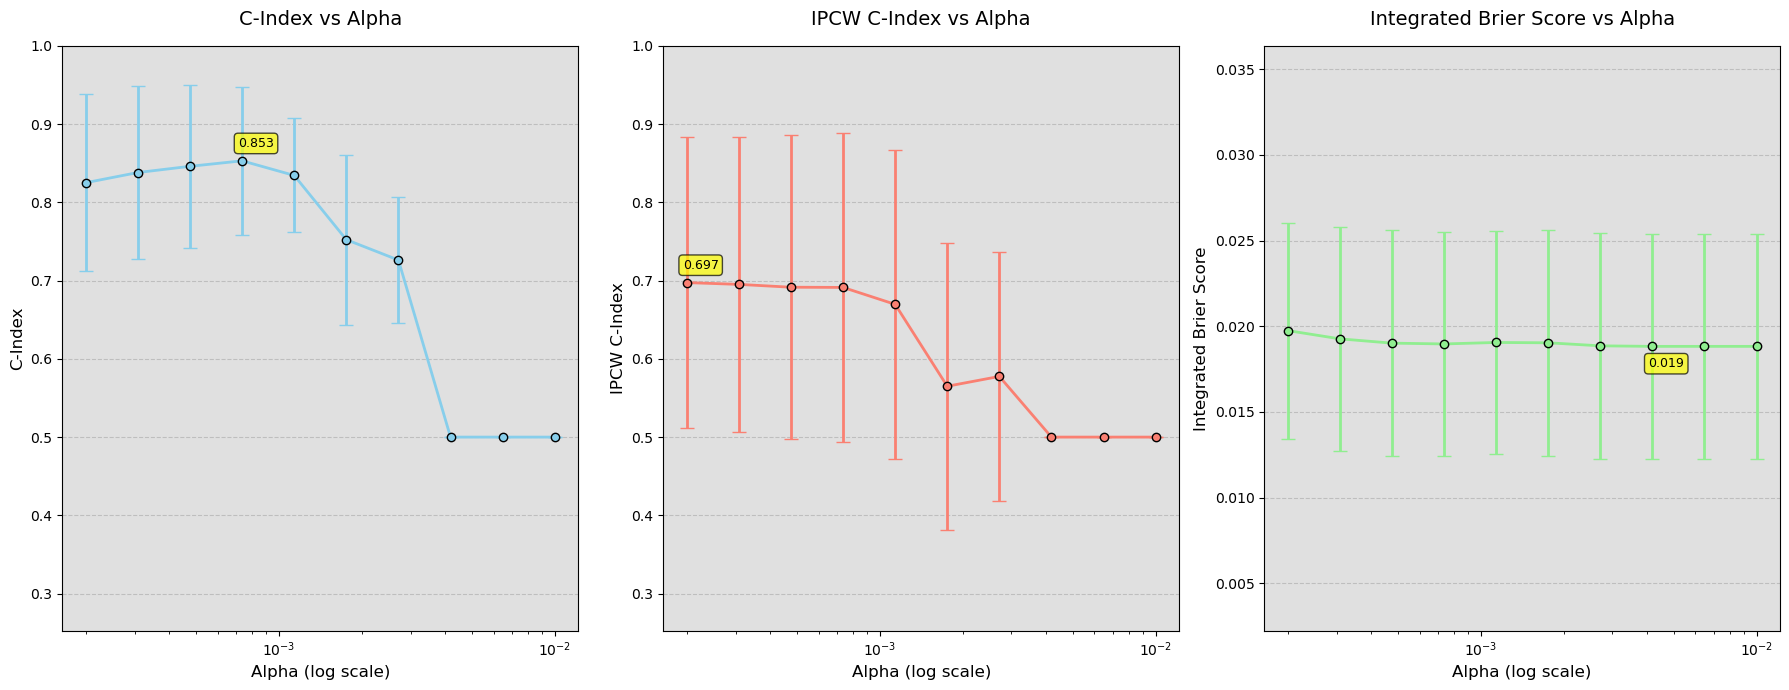

In [82]:
# Plot the results to visualize alpha performance with improved aesthetics
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Set the background color of the figure
fig.patch.set_facecolor('None')

# Calculate global y-axis limits for consistent scaling
# For C-Index and IPCW C-Index (higher is better)
all_cindex_values = list(cindex_summary['Mean']) + list(ipcw_summary['Mean'])
all_cindex_stds = list(cindex_summary['Std']) + list(ipcw_summary['Std'])
cindex_min = min(all_cindex_values) - max(all_cindex_stds) - 0.05
cindex_max = max(all_cindex_values) + max(all_cindex_stds) + 0.05
cindex_min = max(0, cindex_min)  # Don't go below 0
cindex_max = min(1, cindex_max)  # Don't go above 1

# For Brier Score (lower is better) - keep its own scale but don't auto-fit
brier_min = brier_summary['Mean'].min() - brier_summary['Std'].max() - 0.01
brier_max = brier_summary['Mean'].max() + brier_summary['Std'].max() + 0.01

# C-Index plot
axes[0].set_facecolor('#e0e0e0')
axes[0].errorbar(cindex_summary['Alpha'], cindex_summary['Mean'], 
                yerr=cindex_summary['Std'], fmt='o-', capsize=5, color='skyblue', 
                markeredgecolor='black', linewidth=2, markersize=6)
axes[0].set_xscale('log')
axes[0].set_xlabel('Alpha (log scale)', fontsize=12)
axes[0].set_ylabel('C-Index', fontsize=12)
axes[0].set_title('C-Index vs Alpha', fontsize=14, pad=15)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
axes[0].set_ylim(cindex_min, cindex_max)

# IPCW C-Index plot
axes[1].set_facecolor('#e0e0e0')
axes[1].errorbar(ipcw_summary['Alpha'], ipcw_summary['Mean'], 
                yerr=ipcw_summary['Std'], fmt='o-', capsize=5, color='salmon',
                markeredgecolor='black', linewidth=2, markersize=6)
axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (log scale)', fontsize=12)
axes[1].set_ylabel('IPCW C-Index', fontsize=12)
axes[1].set_title('IPCW C-Index vs Alpha', fontsize=14, pad=15)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
axes[1].set_ylim(cindex_min, cindex_max)  # Same scale as C-Index

# Brier Score plot
axes[2].set_facecolor('#e0e0e0')
axes[2].errorbar(brier_summary['Alpha'], brier_summary['Mean'], 
                yerr=brier_summary['Std'], fmt='o-', capsize=5, color='lightgreen',
                markeredgecolor='black', linewidth=2, markersize=6)
axes[2].set_xscale('log')
axes[2].set_xlabel('Alpha (log scale)', fontsize=12)
axes[2].set_ylabel('Integrated Brier Score', fontsize=12)
axes[2].set_title('Integrated Brier Score vs Alpha', fontsize=14, pad=15)
axes[2].grid(axis='y', linestyle='--', alpha=0.7)
axes[2].set_ylim(brier_min, brier_max)  # Fixed range, not auto-fitted

# Add value annotations for best performing alphas
# C-Index best value
best_cindex_idx = cindex_summary['Mean'].idxmax()
best_cindex_alpha = cindex_summary.loc[best_cindex_idx, 'Alpha']
best_cindex_value = cindex_summary.loc[best_cindex_idx, 'Mean']
axes[0].annotate(f'{best_cindex_value:.3f}', 
                xy=(best_cindex_alpha, best_cindex_value),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9, ha='center')

# IPCW best value
best_ipcw_idx = ipcw_summary['Mean'].idxmax()
best_ipcw_alpha = ipcw_summary.loc[best_ipcw_idx, 'Alpha']
best_ipcw_value = ipcw_summary.loc[best_ipcw_idx, 'Mean']
axes[1].annotate(f'{best_ipcw_value:.3f}', 
                xy=(best_ipcw_alpha, best_ipcw_value),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9, ha='center')

# Brier best value (minimum)
best_brier_idx = brier_summary['Mean'].idxmin()
best_brier_alpha = brier_summary.loc[best_brier_idx, 'Alpha']
best_brier_value = brier_summary.loc[best_brier_idx, 'Mean']
axes[2].annotate(f'{best_brier_value:.3f}', 
                xy=(best_brier_alpha, best_brier_value),
                xytext=(10, -15), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9, ha='center')

plt.tight_layout()
plt.show()

In [83]:
# Evaluate best alphas on test set
print("=== TEST SET EVALUATION WITH BEST ALPHAS ===\n")

# Test set results for each metric's best alpha
test_results = {}

# 1. C-Index best alpha
print("1. Testing C-Index best alpha...")
cindex_best_alpha = find_best_alpha(cindex_summary, "C-Index", higher_is_better=True)
model_cindex = CoxnetSurvivalAnalysis(alphas=[cindex_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_cindex.fit(x_train, y_train)

# Get test predictions
predicted_risk_cindex = model_cindex.predict(x_test)

# Calculate all metrics for this model
test_cindex = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_cindex)[0]
max_time = min(y_train['time'].max(), y_test['time'].max()) * 0.9
test_ipcw_cindex = concordance_index_ipcw(y_train, y_test, predicted_risk_cindex, tau=max_time)[0]

# Brier score
surv_funcs_cindex = model_cindex.predict_survival_function(x_test)
times = np.array([2*365, 5*365, 10*365])
times = times[times <= max_time]
if len(times) > 0:
    predicted_survival_probs_cindex = np.asarray([[fn(t) for t in times] for fn in surv_funcs_cindex])
    test_brier_cindex = integrated_brier_score(y_train, y_test, predicted_survival_probs_cindex, times)
else:
    test_brier_cindex = np.nan

test_results['c-index_best'] = {
    'alpha': cindex_best_alpha,
    'c-index': test_cindex,
    'c-index-ipcw': test_ipcw_cindex,
    'int-brier-score': test_brier_cindex,
    'n_features': np.sum(model_cindex.coef_.flatten() != 0)
}

print(f"Alpha: {cindex_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_cindex:.4f}")
print(f"Test Brier Score: {test_brier_cindex:.4f}")
print(f"Selected Features: {test_results['c-index_best']['n_features']}")
print("-" * 50)

=== TEST SET EVALUATION WITH BEST ALPHAS ===

1. Testing C-Index best alpha...
Best alpha for C-Index: 0.0007
Score: 0.8530 ± 0.0949
Alpha: 0.0007
Test C-Index: 0.8178
Test IPCW C-Index: 0.6354
Test Brier Score: 0.0096
Selected Features: 16
--------------------------------------------------


In [84]:
# 2. IPCW C-Index best alpha
print("2. Testing IPCW C-Index best alpha...")
ipcw_best_alpha = find_best_alpha(ipcw_summary, "IPCW C-Index", higher_is_better=True)
model_ipcw = CoxnetSurvivalAnalysis(alphas=[ipcw_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_ipcw.fit(x_train, y_train)

predicted_risk_ipcw = model_ipcw.predict(x_test)
test_cindex_ipcw = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_ipcw)[0]
test_ipcw_ipcw = concordance_index_ipcw(y_train, y_test, predicted_risk_ipcw, tau=max_time)[0]

surv_funcs_ipcw = model_ipcw.predict_survival_function(x_test)
if len(times) > 0:
    predicted_survival_probs_ipcw = np.asarray([[fn(t) for t in times] for fn in surv_funcs_ipcw])
    test_brier_ipcw = integrated_brier_score(y_train, y_test, predicted_survival_probs_ipcw, times)
else:
    test_brier_ipcw = np.nan

test_results['ipcw_best'] = {
    'alpha': ipcw_best_alpha,
    'c-index': test_cindex_ipcw,
    'c-index-ipcw': test_ipcw_ipcw,
    'int-brier-score': test_brier_ipcw,
    'n_features': np.sum(model_ipcw.coef_.flatten() != 0)
}

print(f"Alpha: {ipcw_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex_ipcw:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_ipcw:.4f}")
print(f"Test Brier Score: {test_brier_ipcw:.4f}")
print(f"Selected Features: {test_results['ipcw_best']['n_features']}")
print("-" * 50)

2. Testing IPCW C-Index best alpha...
Best alpha for IPCW C-Index: 0.0002
Score: 0.6974 ± 0.1863
Alpha: 0.0002
Test C-Index: 0.8050
Test IPCW C-Index: 0.6290
Test Brier Score: 0.0092
Selected Features: 30
--------------------------------------------------


In [85]:
# 3. Brier Score best alpha
print("3. Testing Brier Score best alpha...")
brier_best_alpha = find_best_alpha(brier_summary, "Brier Score", higher_is_better=False)
model_brier = CoxnetSurvivalAnalysis(alphas=[brier_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_brier.fit(x_train, y_train)

predicted_risk_brier = model_brier.predict(x_test)
test_cindex_brier = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_brier)[0]
test_ipcw_brier = concordance_index_ipcw(y_train, y_test, predicted_risk_brier, tau=max_time)[0]

surv_funcs_brier = model_brier.predict_survival_function(x_test)
if len(times) > 0:
    predicted_survival_probs_brier = np.asarray([[fn(t) for t in times] for fn in surv_funcs_brier])
    test_brier_brier = integrated_brier_score(y_train, y_test, predicted_survival_probs_brier, times)
else:
    test_brier_brier = np.nan

test_results['brier_best'] = {
    'alpha': brier_best_alpha,
    'c-index': test_cindex_brier,
    'c-index-ipcw': test_ipcw_brier,
    'int-brier-score': test_brier_brier,
    'n_features': np.sum(model_brier.coef_.flatten() != 0)
}

print(f"Alpha: {brier_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex_brier:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_brier:.4f}")
print(f"Test Brier Score: {test_brier_brier:.4f}")
print(f"Selected Features: {test_results['brier_best']['n_features']}")
print("-" * 50)

3. Testing Brier Score best alpha...
Best alpha for Brier Score: 0.0042
Score: 0.0188 ± 0.0066
Alpha: 0.0042
Test C-Index: 0.7503
Test IPCW C-Index: 0.7212
Test Brier Score: 0.0101
Selected Features: 5
--------------------------------------------------


In [86]:
# Create summary table of test results
print("=== SUMMARY OF TEST SET RESULTS ===")
test_summary = pd.DataFrame(test_results).T
test_summary.index = ['Best for C-Index', 'Best for IPCW C-Index', 'Best for Brier Score']

# Round for better display
test_summary_display = test_summary.copy()
for col in ['c-index', 'c-index-ipcw', 'int-brier-score']:
    test_summary_display[col] = test_summary_display[col].round(4)
test_summary_display['alpha'] = test_summary_display['alpha'].round(4)

print(test_summary_display)

# Highlight the best performance for each metric
print("\n=== BEST TEST PERFORMANCE BY METRIC ===")
print(f"Best C-Index: {test_summary['c-index'].max():.4f} (Alpha: {test_summary.loc[test_summary['c-index'].idxmax(), 'alpha']:.4f})")
print(f"Best IPCW C-Index: {test_summary['c-index-ipcw'].max():.4f} (Alpha: {test_summary.loc[test_summary['c-index-ipcw'].idxmax(), 'alpha']:.4f})")
print(f"Best Brier Score: {test_summary['int-brier-score'].min():.4f} (Alpha: {test_summary.loc[test_summary['int-brier-score'].idxmin(), 'alpha']:.4f})")

=== SUMMARY OF TEST SET RESULTS ===
                        alpha  c-index  c-index-ipcw  int-brier-score  \
Best for C-Index       0.0007   0.8178        0.6354           0.0096   
Best for IPCW C-Index  0.0002   0.8050        0.6290           0.0092   
Best for Brier Score   0.0042   0.7503        0.7212           0.0101   

                       n_features  
Best for C-Index             16.0  
Best for IPCW C-Index        30.0  
Best for Brier Score          5.0  

=== BEST TEST PERFORMANCE BY METRIC ===
Best C-Index: 0.8178 (Alpha: 0.0007)
Best IPCW C-Index: 0.7212 (Alpha: 0.0042)
Best Brier Score: 0.0092 (Alpha: 0.0002)


In [87]:
# Show selected features for each best alpha model
print("=== SELECTED FEATURES BY BEST ALPHA MODELS ===\n")

# Get the best alphas
best_alpha_cindex = find_best_alpha(cindex_summary, "C-Index", higher_is_better=True)
best_alpha_ipcw = find_best_alpha(ipcw_summary, "IPCW C-Index", higher_is_better=True)
best_alpha_brier = find_best_alpha(brier_summary, "Brier Score", higher_is_better=False)

# Train models with best alphas and get selected features
models_features = {}

# 1. C-Index best alpha model
print(f"1. C-INDEX BEST ALPHA MODEL (α = {best_alpha_cindex:.4f}):")
model_cindex = CoxnetSurvivalAnalysis(alphas=[best_alpha_cindex], l1_ratio=l1_ratio, fit_baseline_model=True)
model_cindex.fit(x_train, y_train)

cindex_features = []
for feature, coef in zip(model_cindex.feature_names_in_, model_cindex.coef_.flatten()):
    if coef != 0:
        cindex_features.append({'feature': feature, 'coefficient': coef})

cindex_features_df = pd.DataFrame(cindex_features).sort_values('coefficient', key=abs, ascending=False)
models_features['c-index'] = cindex_features_df

print(f"   Number of selected features: {len(cindex_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in cindex_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(cindex_features_df) > 10:
    print(f"     ... and {len(cindex_features_df) - 10} more features")
print()

# 2. IPCW C-Index best alpha model
print(f"2. IPCW C-INDEX BEST ALPHA MODEL (α = {best_alpha_ipcw:.4f}):")
model_ipcw = CoxnetSurvivalAnalysis(alphas=[best_alpha_ipcw], l1_ratio=l1_ratio, fit_baseline_model=True)
model_ipcw.fit(x_train, y_train)

ipcw_features = []
for feature, coef in zip(model_ipcw.feature_names_in_, model_ipcw.coef_.flatten()):
    if coef != 0:
        ipcw_features.append({'feature': feature, 'coefficient': coef})

ipcw_features_df = pd.DataFrame(ipcw_features).sort_values('coefficient', key=abs, ascending=False)
models_features['c-index-ipcw'] = ipcw_features_df

print(f"   Number of selected features: {len(ipcw_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in ipcw_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(ipcw_features_df) > 10:
    print(f"     ... and {len(ipcw_features_df) - 10} more features")
print()

# 3. Brier Score best alpha model
print(f"3. BRIER SCORE BEST ALPHA MODEL (α = {best_alpha_brier:.4f}):")
model_brier = CoxnetSurvivalAnalysis(alphas=[best_alpha_brier], l1_ratio=l1_ratio, fit_baseline_model=True)
model_brier.fit(x_train, y_train)

brier_features = []
for feature, coef in zip(model_brier.feature_names_in_, model_brier.coef_.flatten()):
    if coef != 0:
        brier_features.append({'feature': feature, 'coefficient': coef})

brier_features_df = pd.DataFrame(brier_features).sort_values('coefficient', key=abs, ascending=False)
models_features['int-brier-score'] = brier_features_df

print(f"   Number of selected features: {len(brier_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in brier_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(brier_features_df) > 10:
    print(f"     ... and {len(brier_features_df) - 10} more features")
print()

# Feature overlap analysis
print("=== FEATURE SELECTION OVERLAP ANALYSIS ===")
cindex_set = set(cindex_features_df['feature'])
ipcw_set = set(ipcw_features_df['feature'])
brier_set = set(brier_features_df['feature'])

# Common features across all models
common_all = cindex_set & ipcw_set & brier_set
print(f"Features selected by ALL models: {len(common_all)}")
if common_all:
    print(f"   {list(common_all)}")

# Pairwise overlaps
common_cindex_ipcw = cindex_set & ipcw_set
common_cindex_brier = cindex_set & brier_set
common_ipcw_brier = ipcw_set & brier_set

print(f"\nFeatures selected by C-Index AND IPCW models: {len(common_cindex_ipcw)}")
print(f"Features selected by C-Index AND Brier models: {len(common_cindex_brier)}")
print(f"Features selected by IPCW AND Brier models: {len(common_ipcw_brier)}")

# Unique features
unique_cindex = cindex_set - ipcw_set - brier_set
unique_ipcw = ipcw_set - cindex_set - brier_set
unique_brier = brier_set - cindex_set - ipcw_set

print(f"\nFeatures UNIQUE to C-Index model: {len(unique_cindex)}")
print(f"Features UNIQUE to IPCW model: {len(unique_ipcw)}")
print(f"Features UNIQUE to Brier model: {len(unique_brier)}")

=== SELECTED FEATURES BY BEST ALPHA MODELS ===

Best alpha for C-Index: 0.0007
Score: 0.8530 ± 0.0949
Best alpha for IPCW C-Index: 0.0002
Score: 0.6974 ± 0.1863
Best alpha for Brier Score: 0.0042
Score: 0.0188 ± 0.0066
1. C-INDEX BEST ALPHA MODEL (α = 0.0007):
   Number of selected features: 16
   Selected features (sorted by absolute coefficient value):
     Adjuvant therapy with bio drugs: -1.8707
     Oestrogen receptor status at CB: -1.5553
     Endocrine therapy performed: 1.2426
     Grade at CB: 0.8382
     Istotype at CB_1.0: -0.5060
     Radiotherapy on supraclavicular area: 0.4866
     Side location of the lesion: -0.3833
     N (Regional nodes affected): 0.3156
     Radiotherapy (RT) performed: -0.1446
     cT_T2: 0.1235
     ... and 6 more features

2. IPCW C-INDEX BEST ALPHA MODEL (α = 0.0002):
   Number of selected features: 30
   Selected features (sorted by absolute coefficient value):
     Adjuvant therapy with bio drugs: -3.1250
     Oestrogen receptor status at CB: -